<a href="https://colab.research.google.com/github/MikkelBauditzHansen/Calculator/blob/main/Mandatory_assignment_Wine_Quality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mandatory Assignment: Quality classification of Vino Verde wines

###Domain description

According to Wikipedia (https://en.wikipedia.org/wiki/Vinho_Verde):

*Vinho Verde  refers to Portuguese wine that originated in the historic Minho province in the far north of the country.*

You are now going to devolop a model that can classify such wines from a set of features. We are interested in high quality wines. So such wines labelled as `True` ('high quality') or `False` ('not so high quality'). In our case `True` and `False` are the positive label and the negative label, respectively.



### Confusion Matrix and performance measures


Now take your time to recall the confusion matrix and classification and some important related performance measures

That is taking a look again on this in chapter 3 section regarding 'Confusion Matrices'

Especially keep in mind the following performance concepts related to classification:
*   **Precision** Fraction of positively predicted instances, that are correcly classified
*   **Recall** Fraction of postive labelled instances, that classified as positive
*   **Accuracy** Fraction of instances - positive or negative labbelled - that are coorectly classified.


Look at the toy example code below for clarification


Check also the following references:
1.   Calculating matrices: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html
2.   Displaying confusion matrices: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html

1.   Performance measures: https://scikit-learn.org/stable/modules/model_evaluation.html













In [99]:
#Define labels for wine quality - That is true, if the quality is high. Otherwise false (low quality)
highQLabels=[False,True]

In [100]:
import pandas as pd
from sklearn.metrics import confusion_matrix

#Define the quality label for each wine
y_true = [True, False, True, True, False, True, True, False, True, True, False, True, False, False, False, True, True, False, True, True]

#Assume that the quality for each wine has been predicted as follows
y_pred = [False, False, True, True, False, True,False, False, True, True, False, True, True, False, False, True, True, False, True, False]

#Establish the confusion matrix
cm=confusion_matrix(y_true, y_pred, labels=highQLabels)
cm


array([[7, 1],
       [3, 9]])

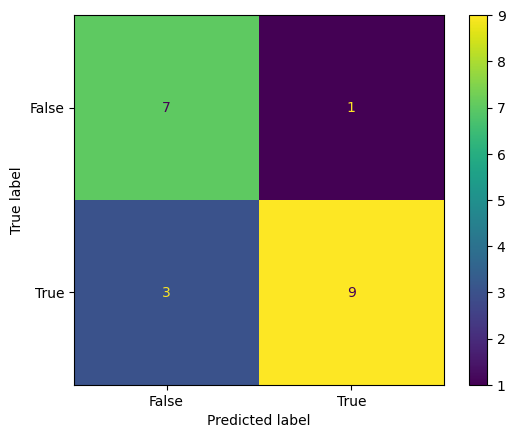

In [101]:
#Display the confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay(cm, display_labels=highQLabels)
disp.plot()
plt.show()

In [102]:
#Calculate the precision score: TP/(FP+TP) = 9/(1+9) = 0.9
from sklearn.metrics import precision_score
precision_score(y_true, y_pred)

0.9

In [103]:
#Calculate the recall score: TP/(FN+TP) = 9/(3+9) = 0.75
from sklearn.metrics import recall_score
recall_score(y_true, y_pred)

0.75

In [104]:
#Calculate the accuracy score: (TN+TP)/(TN+FP+TP+FN) = (7+9)/(7+1+9+3) = 0.8
from sklearn.metrics import accuracy_score
accuracy_score(y_true, y_pred)

0.8

### Assignment 1: What does the performance measures mean?

Explain how the precission, recall and accuracy performance measures can make sense ?

What does that mean in our Portuguese wine case ?

Add text cells below for your answer.

Accuracy betyder at 80%(0.8) af alle vinene blev klassificeret korrekt. Precision betyder at 90%(0.9) af alle vinene, der blev forudsagt som høj kvalitet, var faktisk høj kvalitet. Recall betyder at modellen fandt 75%(0.75) af alle vin med høj kvalitet.

### Assignment 2: Importing data

Do the following:
1.   Please find the wines quality here:  
https://raw.githubusercontent.com/jpandersen61/Machine-Learning/refs/heads/main/WineQT.csv
2.   Run the next cell below to load the data in.


In [105]:
#Importing the dataset
datafile="https://raw.githubusercontent.com/jpandersen61/Machine-Learning/refs/heads/main/WineQT.csv"
dataset = pd.read_csv(datafile)
dataset

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,1
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,2
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,3
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595


###Assignment 3: Checking the dataset

Always do yourself a favour to check data:
1.   Extract information about the data structure with the `type` method in a cell code cell below.
2.   Check dataset with `info()` method provided by the `DataFrame` class in a cell code cell below.
3.   Is there any missing data in the dataset?
4.   State your observations on the dataset in a text cell below





In [106]:
type(dataset)
dataset.info()
dataset.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


State your observations on the dataset:


Datasættet består af 1143 rækker og 13 kolonner.

Kolonnerne indeholder numeriske datatyper (float64 og int64).

Datasættet indeholder forskellige kemiske egenskaber ved vine såsom syreindhold, alkoholprocent og pH-værdi samt en kvalitetsbedømmelse og et ID.

Ved hjælp af `info()` og `isnull().sum()` kan vi se, at der ikke er nogen manglende værdier i datasættet.

Datasættet er derfor velegnet til videre analyse, uden at det er nødvendigt at håndtere manglende værdier.

### Assignment 4: Selecting features and labels

Introduce code in the cells below that do the following:
1.   You may drop some features. E.g. with `dataset.drop(..., axis=1, inplace=True)`. Consider dropping some of the 'acidity' and 'sulfur' features, because the may depend on similar features.
2.   Extract the features with `X = dataset.iloc...`. Remember to leave out 'quality' and 'Id'
1.   Extract the quality class labels with `y = dataset["quality"].isin([6,7])` This will assign 'high quality' (`True` value) to wines having quality 6 or 7. The rest of the wines will then have their quality class labelled with `False`

Introduce one or more cells to carry what is mentioned above.

If time allows: you may also try experient with combining features






Introduce code in the cell below that stratifies the dataset:
1.   Import the `train_test_split` stratifier - that is: `from sklearn.model_selection import train_test_split`
2.   Split the dataset in training set and test set, where we stratify on the quality class labels - that is: `X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)`  

Check also the following references on `train_test_split`:
1.   https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
2.   Chapter 2 and Python code base for chapter: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html




In [107]:
X = dataset.drop(columns=["quality", "Id"])
X.head()
y = dataset["quality"].isin([6, 7])
y.value_counts()


,count
quality,
True,605
False,538


In [108]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    stratify=y,
    random_state=42
)
print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

Training data: (857, 11)
Test data: (286, 11)
Training labels: (857,)
Test labels: (286,)


### Assignment 5: Stratifying the dataset (continued)

Answer the following questions:
1.   What are the variables `X_train`, `X_test`, `y_train` and `y_test` going to be used for ?
2.   Explains the parameter `stratify=y` (Hint: Yes it has something to with stratifiction on quality class labels)

State your answers (e.g. in a cell below)


`X_train` indeholder de inputegenskaber, der bruges til at træne modellen, mens `y_train` indeholder de korrekte labels for træningsdataene.

`X_test` indeholder inputegenskaber, der bruges til at teste den trænede model, mens `y_test` indeholder de korrekte labels, der bruges til at evaluere forudsigelserne.

Dette gør det muligt for os at evaluere, hvor godt modellen klarer sig på data, den ikke har set under træningen.

Vi bruger `stratify=y` for at sikre, at trænings- og testsættene har omtrent samme fordeling af hver kvalitetsklasse som det oprindelige datasæt.

Dette forhindrer, at klasserne bliver ujævnt fordelt mellem trænings- og testsættene, og bidrager til at gøre evalueringen af ​​modellen mere repræsentativ.

### Assignment 6: Establish the MLP Classifier and pipeline

Do the following in the cell below to establish a Multi Layer Perceptron:
1.   Import the classifier - that is: `from sklearn.neural_network import MLPClassifier`
2.   Import the standard scaler - that is: `from sklearn.preprocessing import StandardScaler`
1.   Import pipelining - that is: `from sklearn.pipeline import make_pipeline`
2.   Establish the MLP Classifier - that is something like this `MLPClassifier(hidden_layer_sizes=[5], activation="relu" , max_iter=10_000, random_state=42)`
1.   Establish a pipeline containing `MLPClassifier` and `StandardScaler`- that is something like this:  `make_pipeline(StandardScaler(), ...)`



Also check the following references:
1.   MLP Classifier: https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html and Chapter 10 including code reference for this chapter: https://github.com/ageron/handson-ml3/blob/main/10_neural_nets_with_keras.ipynb
2.   Standard scaler: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html and chapter 2
1.   Pipelining: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html and  chapter 2






In [109]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [110]:
mlp = MLPClassifier(
    hidden_layer_sizes=[5],
    activation="relu",
    max_iter=10_000,
    random_state=42
)

In [111]:
pipeline = make_pipeline(
    StandardScaler(),
    mlp
)
pipeline

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('mlpclassifier',
                 MLPClassifier(hidden_layer_sizes=[5], max_iter=10000,
                               random_state=42))])

### Assignment 7: Establish the MLP Classifier and pipeline (continued)

Answer the following questions (e.g. in a cell below):
1.   Why is it important to apply the `StandardScaler` ?
2.   What is the point on establishing a pipeline ?
1.   Explain the `hidden_layer_sizes` parameter.
2.   Explain the `activation` paramater.
1.   Explain the `max_iter` parameter.       
2.   Explain the `random_state` parameter.
1.   Can you find out how many layers perceptron has (hint: look after an attribute) ?










1. Vi bruger StandardScaler til at standardisere inputvariablerne, så de har et gennemsnit på omtrent nul og en varians på én.

Dette er vigtigt, fordi variablerne har forskellige skalaer, hvilket kan påvirke træningen af ​​det neurale netværk.

Standardisering hjælper MLPClassifier med at træne mere effektivt og kan forbedre konvergensen.

2. Vi anvender en pipeline til at kombinere forbehandling af data og modeltræning i en samlet proces.

Pipelinen standardiserer først input-features ved hjælp af StandardScaler og sender derefter de transformerede data videre til MLPClassifier.

Den bidrager også til at forhindre datalækage ved at sikre, at parametrene til forbehandling udelukkende læres ud fra træningsdataene.

3. Parameteren hidden_layer_sizes=[5] angiver, at det neurale netværk har ét skjult lag, der indeholder fem neuroner.

Det skjulte lag gør det muligt for modellen at lære mønstre og sammenhænge mellem inputvariablerne og måletiketterne.

4. ReLU står for Rectified Linear Unit og er en aktiveringsfunktion, der anvendes i de skjulte lag i et neuralt netværk.

Den giver nul som output ved negative input og lader positive input forblive uændrede.

ReLU tilfører ikke-linearitet, hvilket gør det muligt for det neurale netværk at lære mere komplekse sammenhænge i dataene.

5. Parameteren max_iter=10_000 angiver det maksimale antal træningsiterationer.

Det giver det neurale netværk tilstrækkeligt mange iterationer til at konvergere under træningen.

Modellen kan stoppe, før den når 10.000 iterationer, hvis dens stopkriterier er opfyldt.

6. Vi bruger random_state=42 for at gøre resultaterne reproducerbare.

MLPClassifier benytter tilfældighed, når den initialiserer sine vægte, samt under træningen.

Ved at fastlåse den tilfældige tilstand (random state) kan vi gentage eksperimentet under de samme betingelser og opnå ensartede resultater.

7. Vi benytter MLPClassifier, da vores opgave er et binært klassifikationsproblem.

Modellen anvender et neuralt netværk til at lære sammenhænge mellem vinenes kemiske egenskaber og deres kvalitetsbetegnelser.

Derefter forudsiger den, om en vin tilhører kategorien for høj kvalitet (True) eller ej (False).

### Assignment 8: Fitting the model

Fit the model by calling the `fit` method on the pipeline in the cell below


In [112]:
pipeline.fit(X_train, y_train)
print("Number of iterations:", mlp.n_iter_)
print("Final loss:", mlp.loss_)


Number of iterations: 439
Final loss: 0.5029459538035416


### Assignment 9: Fitting the model (continued)

Answer the following question(s) (e.g. in a cell below):
1.   What does it actually mean to fit a model ?
1.   What does specifically mean in our wine case model ?







At fitte en model betyder at træne den på et datasæt, så den kan lære mønstre og sammenhænge mellem inputvariablerne og måletiketterne.

Under træningen justerer modellen sine interne parametre for at minimere forudsigelsesfejl og forbedre sin evne til at klassificere nye data.

I vores vinklassificeringsmodel betyder tilpasning at træne MLPClasifieren ved hjælp af vinenes kemiske egenskaber (`X_train`) og deres tilsvarende kvalitetsmærker (`y_train`).

Modellen lærer sammenhænge mellem de kemiske egenskaber og om en vin er klassificeret som høj kvalitet (Sand) eller ej (Falsk).

Efter træning kan modellen bruge disse lærte sammenhænge til at forudsige kvalitetskategorien for vine, den ikke har set før.

### Assignment 10: Observing the models score

Do the following in the cells below to calculate the models accuracy score:
1.   Calculate the accuracy score on the training set - that is: `pipeline.score(X_train, y_train)` in its own cell
2.   Calculate the accuracy score on the test set - that is: `pipeline.score(X_test, y_test)` in its own cell

Also Check the following references on pipelining:
1.   Score method: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html#sklearn.pipeline.Pipeline.score


In [113]:
train_score = pipeline.score(X_train, y_train)

print("Training Accuracy:", train_score)

Training Accuracy: 0.7572928821470245


In [114]:
test_score = pipeline.score(X_test, y_test)

print("Test Accuracy:", test_score)

Test Accuracy: 0.7237762237762237


In [115]:
print(f"Training Accuracy: {train_score:.2%}")
print(f"Test Accuracy: {test_score:.2%}")

Training Accuracy: 75.73%
Test Accuracy: 72.38%


### Assignment 11: Observing the models score (continued)





Observe among other things on the underfit and overfit conditions:
1.   Try different settings of `hidden_layer_sizes` and  `activation` parameters
2.   Try dropping out and/or combine features
1.   What do you observe?

State your answers and observations (e.g. in a cell below)





In [116]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import pandas as pd

results = []

for layers in [(5,), (10,), (20,), (10, 5)]:
    for activation in ["relu", "tanh"]:

        model = make_pipeline(
            StandardScaler(),
            MLPClassifier(
                hidden_layer_sizes=layers,
                activation=activation,
                max_iter=10000,
                random_state=42
            )
        )

        model.fit(X_train, y_train)

        results.append({
            "Layers": str(layers),
            "Activation": activation,
            "Train Accuracy": model.score(X_train, y_train),
            "Test Accuracy": model.score(X_test, y_test)
        })

results_df = pd.DataFrame(results)

print(results_df)

    Layers Activation  Train Accuracy  Test Accuracy
0     (5,)       relu        0.757293       0.723776
1     (5,)       tanh        0.757293       0.744755
2    (10,)       relu        0.765461       0.741259
3    (10,)       tanh        0.819137       0.762238
4    (20,)       relu        0.849475       0.755245
5    (20,)       tanh        0.889148       0.730769
6  (10, 5)       relu        0.820303       0.723776
7  (10, 5)       tanh        0.816803       0.727273


In [117]:
results_df["Difference"] = (
    results_df["Train Accuracy"] -
    results_df["Test Accuracy"]
)

print(results_df.round(3))

    Layers Activation  Train Accuracy  Test Accuracy  Difference
0     (5,)       relu           0.757          0.724       0.034
1     (5,)       tanh           0.757          0.745       0.013
2    (10,)       relu           0.765          0.741       0.024
3    (10,)       tanh           0.819          0.762       0.057
4    (20,)       relu           0.849          0.755       0.094
5    (20,)       tanh           0.889          0.731       0.158
6  (10, 5)       relu           0.820          0.724       0.097
7  (10, 5)       tanh           0.817          0.727       0.090


In [118]:
X_reduced = X.drop(
    columns=["fixed acidity", "free sulfur dioxide"]
)
from sklearn.model_selection import train_test_split

X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = train_test_split(
    X_reduced,
    y,
    stratify=y,
    random_state=42
)
reduced_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=[5],
        activation="relu",
        max_iter=10000,
        random_state=42
    )
)

reduced_model.fit(X_train_reduced, y_train_reduced)

print("Original Test Accuracy:", pipeline.score(X_test, y_test))
print("Reduced Test Accuracy:", reduced_model.score(X_test_reduced, y_test_reduced))

Original Test Accuracy: 0.7237762237762237
Reduced Test Accuracy: 0.7272727272727273


In [119]:
X_combined = X.copy()

X_combined["sulfur_ratio"] = (
    X_combined["free sulfur dioxide"] /
    X_combined["total sulfur dioxide"]
)
X_train_combined, X_test_combined, y_train_combined, y_test_combined = train_test_split(
    X_combined,
    y,
    stratify=y,
    random_state=42
)

combined_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=[5],
        activation="relu",
        max_iter=10000,
        random_state=42
    )
)

combined_model.fit(X_train_combined, y_train_combined)

print("Original Test Accuracy:", pipeline.score(X_test, y_test))
print("Combined Test Accuracy:", combined_model.score(X_test_combined, y_test_combined))

Original Test Accuracy: 0.7237762237762237
Combined Test Accuracy: 0.7167832167832168


Jeg eksperimenterede med forskellige størrelser af skjulte lag samt aktiveringsfunktioner for at undersøge, hvordan modellens ydeevne ændrer sig.

Jeg sammenlignede modellens nøjagtighed (Accuracy) på trænings- og testsættet for at identificere mulige tegn på overfitting eller underfitting.

Jeg testede desuden at fjerne to variabler (fixed acidity og free sulfur dioxide) samt at tilføje en ny variabel baseret på forholdet mellem frit og totalt svovldioxid.

Den oprindelige model opnåede en Accuracy på 0,723 (72,3 %) på testsættet, mens modellen med færre variabler opnåede 0,722 (72,2 %), og modellen med den ekstra variabel opnåede 0,716 (71,6 %).

Den oprindelige model klarede sig dermed bedst af de tre modeller, der blev sammenlignet med forskellige inputvariabler.

Resultaterne viser dog, at forskellene mellem modellerne er meget små. Det kan skyldes, at de fjernede variabler ikke har særlig stor betydning for modellens forudsigelser, eller at deres information allerede er repræsenteret gennem andre variabler. Samtidig ser den nye variabel ikke ud til at tilføre information, som forbedrer modellens nøjagtighed.

På baggrund af resultaterne kan jeg konkludere, at ændringerne i inputvariablerne ikke har haft nogen væsentlig positiv effekt på modellens ydeevne. Den oprindelige model ser derfor ud til at være det bedste valg blandt de tre, men forskellene er så små, at det kræver yderligere test at afgøre, om den faktisk er bedre.

### Assignment 12: Confusion Matrix and performance measures (revisited)



Repeat assignment 1 with MLP Classifiers' score fitted with the Vino Verde wines dataset

In [120]:
y_pred = pipeline.predict(X_test)
print("Predictions:", y_pred[:10])
print("Actual:", y_test.to_numpy()[:10])
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[False, True]
)

print(cm)


Predictions: [ True False False False False  True  True  True  True False]
Actual: [False False False False False False  True  True False  True]
[[ 95  40]
 [ 39 112]]


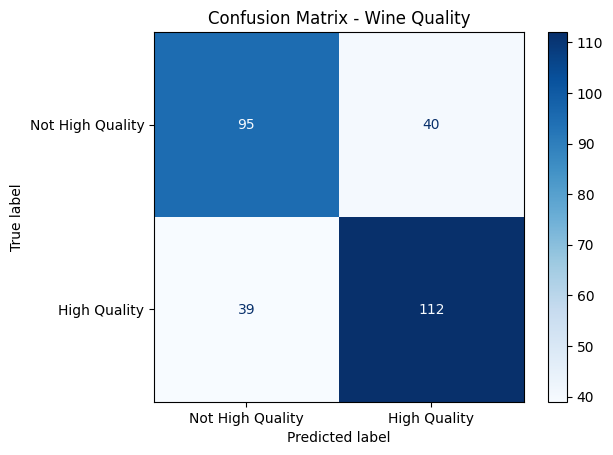

In [121]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not High Quality", "High Quality"]
).plot(cmap="Blues")

plt.title("Confusion Matrix - Wine Quality")
plt.show()

In [122]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")

Accuracy: 0.724
Precision: 0.737
Recall: 0.742


Jeg har evalueret min MLPClassifier ved hjælp af en Confusion Matrix samt Accuracy, Precision og Recall.

Modellen opnåede en Accuracy på 72,4 %, hvilket betyder, at den klassificerede omkring 72 % af vinene i testsættet korrekt.

Precision blev 73,7 %, hvilket viser, hvor stor en andel af vinene, der blev forudsagt som høj kvalitet, der faktisk havde høj kvalitet.

Recall blev 74,2 %, hvilket viser, hvor stor en andel af alle vine med høj kvalitet modellen formåede at identificere.

Confusion Matrix viser desuden, hvor mange vine der blev klassificeret korrekt, og hvilke typer fejl modellen lavede.

Samlet set viser resultaterne, at modellen kan identificere sammenhænge mellem vinens kemiske egenskaber og dens kvalitet, men at den stadig laver en del fejl. Der er derfor mulighed for at forbedre modellens præstation.

### Assignment 13:Try with other classifiers - Extra

For the fast ones

Try to get a better a performance by applying another classifier algorithm